# Solutions: Hypothesis Testing with Z-Scores

## Learning Objectives

By completing these exercises you will practice:

- Computing and interpreting Z-scores
- Performing **one-sample** Z-tests (left-tailed, right-tailed, and two-tailed)
- Performing **two-sample** Z-tests to compare two population means
- Making statistical decisions using both the **p-value approach** and the **critical-value approach**
- Determining the **minimum sample size** needed to detect a given effect

---

### Hypothesis Testing Steps (Quick Reference)

For every exercise, follow these five steps:

1. **State the hypotheses** ($H_0$ and $H_1$)
2. **Set the significance level** ($\alpha$)
3. **Compute the test statistic** (Z-score)
4. **Compute or look up the p-value** (or compare with the critical value)
5. **Make a decision** — reject or fail to reject $H_0$, and state the conclusion in context

In [1]:
import numpy as np
import scipy.stats as stats
import statsmodels.stats.weightstats as st
import matplotlib.pyplot as plt
import seaborn as sns
import math

---

## Exercises

### Exercise 1: Computing Z-Scores (Warm-Up)

A nationwide standardized math exam has a **population mean** $\mu = 72$ and a **population standard deviation** $\sigma = 8$.

Three students scored **85**, **68**, and **72** respectively.

**Tasks:**
1. Compute the Z-score for each student.
2. Interpret each Z-score in plain language (how many standard deviations above/below the mean?).
3. Using `scipy.stats.norm`, find the percentile rank (cumulative probability) for each score.

In [4]:
# Solution for Exercise 1

mu = 72
sigma = 8
scores = [85, 68, 72]

print("=" * 55)
print("Exercise 1: Computing Z-Scores")
print("=" * 55)

for x in scores:
    z = (x - mu) / sigma
    percentile = stats.norm.cdf(z) * 100
    direction = "above" if z > 0 else "below" if z < 0 else "at"
    print(f"\nScore: {x}")
    print(f"  Z-score: {z:.4f}")
    print(f"  Interpretation: {abs(z):.2f} standard deviations {direction} the mean")
    print(f"  Percentile rank: {percentile:.2f}%")

print("\n--- Verify with scipy.stats.zscore ---")
print("Z-scores:", stats.zscore(scores, ddof=0))

Exercise 1: Computing Z-Scores

Score: 85
  Z-score: 1.6250
  Interpretation: 1.62 standard deviations above the mean
  Percentile rank: 94.79%

Score: 68
  Z-score: -0.5000
  Interpretation: 0.50 standard deviations below the mean
  Percentile rank: 30.85%

Score: 72
  Z-score: 0.0000
  Interpretation: 0.00 standard deviations at the mean
  Percentile rank: 50.00%

--- Verify with scipy.stats.zscore ---
Z-scores: [ 1.37794564 -0.96456195 -0.41338369]


---

### Exercise 2: One-Sample Z-Test (Right-Tailed) — Customer Support

A tech company’s historical data shows that the **average resolution time** for customer support tickets is **$\mu = 24$ hours** with a known standard deviation of **$\sigma = 4$ hours**.

After implementing a new AI chatbot, a random sample of **$n = 40$** tickets has a **sample mean resolution time of 25.3 hours**.

Management is concerned the new system may have **increased** resolution time.

**Test at $\alpha = 0.05$ whether the mean resolution time has increased (right-tailed test).**

*Hint: You may compute Z manually or use `statsmodels.stats.weightstats.ztest`.*

In [3]:
# Solution for Exercise 2

mu_0 = 24
sigma = 4
n = 40
x_bar = 25.3
alpha = 0.05

z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = 1 - stats.norm.cdf(z_stat)  # right-tailed
z_critical = stats.norm.ppf(1 - alpha)

print("=" * 55)
print("Exercise 2: One-Sample Z-Test (Right-Tailed)")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu > {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")
print(f"Critical Z:  {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: There is sufficient evidence that the new chatbot")
    print("            increased the mean resolution time.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence that the chatbot increased")
    print("            the mean resolution time.")

Exercise 2: One-Sample Z-Test (Right-Tailed)
H0: mu = 24
H1: mu > 24
alpha = 0.05

Z-statistic: 2.0555
P-value:     0.0199
Critical Z:  1.6449

Decision: Reject H0 (p=0.0199 < alpha=0.05)
Conclusion: There is sufficient evidence that the new chatbot
            increased the mean resolution time.


---

### Exercise 3: One-Sample Z-Test (Left-Tailed) — Manufacturing QA

A pharmaceutical company claims that its vitamin C tablets contain on average **$\mu = 500$ mg** of vitamin C, with a known population standard deviation of **$\sigma = 10$ mg**.

A quality inspector suspects the tablets are **under-dosed**. A random sample of **$n = 60$** tablets yields a sample mean of **497 mg**.

**Test at $\alpha = 0.05$ whether the mean vitamin C content is less than 500 mg (left-tailed test).**

In [ ]:
# Solution for Exercise 3

mu_0 = 500
sigma = 10
n = 60
x_bar = 497
alpha = 0.05

z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = stats.norm.cdf(z_stat)  # left-tailed
z_critical = stats.norm.ppf(alpha)

print("=" * 55)
print("Exercise 3: One-Sample Z-Test (Left-Tailed)")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu < {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")
print(f"Critical Z:  {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: There is sufficient evidence that the tablets are")
    print("            under-dosed (mean < 500 mg).")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence that the mean vitamin C content")
    print("            is less than 500 mg.")

---

### Exercise 4: One-Sample Z-Test (Two-Tailed) — E-Commerce

An online retailer’s records indicate that the **average order value** is **$\mu = \$85$** with $\sigma = \$12$.

After a website redesign, a sample of **$n = 100$** orders shows a mean order value of **$\bar{x} = \$82.50$**.

The product team wants to know if the redesign has **changed** (either increased or decreased) the average order value.

**Test at $\alpha = 0.05$ whether the mean order value is different from $85 (two-tailed test).**

**Additionally:** state the conclusion using both the p-value approach **and** the critical-value approach. Do the two approaches agree?

In [5]:
# Solution for Exercise 4

mu_0 = 85
sigma = 12
n = 100
x_bar = 82.50
alpha = 0.05

z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = 2 * stats.norm.cdf(-abs(z_stat))  # two-tailed
z_critical = stats.norm.ppf(1 - alpha / 2)

print("=" * 55)
print("Exercise 4: One-Sample Z-Test (Two-Tailed)")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu != {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic:  {z_stat:.4f}")
print(f"P-value:      {p_value:.4f}")
print(f"Critical Z:   +/- {z_critical:.4f}")

# P-value approach
print("\n--- P-value approach ---")
if p_value < alpha:
    print(f"Reject H0 (p={p_value:.4f} < alpha={alpha})")
else:
    print(f"Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")

# Critical value approach
print("\n--- Critical-value approach ---")
if abs(z_stat) > z_critical:
    print(f"Reject H0 (|Z|={abs(z_stat):.4f} > Z_crit={z_critical:.4f})")
else:
    print(f"Fail to reject H0 (|Z|={abs(z_stat):.4f} <= Z_crit={z_critical:.4f})")

print("\nBoth approaches agree.")
print("Conclusion: There is sufficient evidence that the website redesign")
print("            changed the average order value.")

Exercise 4: One-Sample Z-Test (Two-Tailed)
H0: mu = 85
H1: mu != 85
alpha = 0.05

Z-statistic:  -2.0833
P-value:      0.0372
Critical Z:   +/- 1.9600

--- P-value approach ---
Reject H0 (p=0.0372 < alpha=0.05)

--- Critical-value approach ---
Reject H0 (|Z|=2.0833 > Z_crit=1.9600)

Both approaches agree.
Conclusion: There is sufficient evidence that the website redesign
            changed the average order value.


---

### Exercise 5: One-Sample Z-Test (Right-Tailed) — Ride-Hailing

A ride-hailing company reports that the **mean trip duration** across a metro area is **$\mu = 18$ minutes** ($\sigma = 5$ minutes).

During a major construction project, a sample of **$n = 50$** trips in the affected zone has a mean of **19.8 minutes**.

**Test at $\alpha = 0.01$ whether the construction has significantly increased trip duration (right-tailed test).**

*Note the stricter significance level.*

In [6]:
# Solution for Exercise 5

mu_0 = 18
sigma = 5
n = 50
x_bar = 19.8
alpha = 0.01

z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = 1 - stats.norm.cdf(z_stat)  # right-tailed
z_critical = stats.norm.ppf(1 - alpha)

print("=" * 55)
print("Exercise 5: One-Sample Z-Test (Right-Tailed)")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu > {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")
print(f"Critical Z:  {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: There is sufficient evidence at alpha=0.01 that")
    print("            construction increased the mean trip duration.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence at alpha=0.01 that")
    print("            construction increased the mean trip duration.")

Exercise 5: One-Sample Z-Test (Right-Tailed)
H0: mu = 18
H1: mu > 18
alpha = 0.01

Z-statistic: 2.5456
P-value:     0.0055
Critical Z:  2.3263

Decision: Reject H0 (p=0.0055 < alpha=0.01)
Conclusion: There is sufficient evidence at alpha=0.01 that
            construction increased the mean trip duration.


---

### Exercise 6: Two-Sample Z-Test — A/B Testing (Marketing)

A marketing team runs an A/B test on email subject lines to compare **average revenue per email**.

| Group | $n$ | Sample Mean ($\bar{x}$) | Known $\sigma$ |
|-------|-----|------------------------|----------------|
| A (Control) | 200 | \$4.20 | \$1.50 |
| B (New Subject Line) | 200 | \$4.65 | \$1.60 |

**Test at $\alpha = 0.05$ whether Group B’s mean revenue per email is higher than Group A’s (right-tailed two-sample Z-test).**

*Hint: Generate synthetic data with `np.random.normal` matching the given stats, or compute the two-sample Z statistic manually.*

In [9]:
# Solution for Exercise 6

n1, x_bar1, sigma1 = 200, 4.20, 1.50
n2, x_bar2, sigma2 = 200, 4.65, 1.60
alpha = 0.05

se = np.sqrt(sigma1**2 / n1 + sigma2**2 / n2)
z_stat = (x_bar2 - x_bar1) / se
p_value = 1 - stats.norm.cdf(z_stat)  # right-tailed (B > A)
z_critical = stats.norm.ppf(1 - alpha)

print("=" * 55)
print("Exercise 6: Two-Sample Z-Test (Right-Tailed)")
print("=" * 55)
print(f"H0: mu_B - mu_A = 0 (no difference)")
print(f"H1: mu_B - mu_A > 0 (Group B is higher)")
print(f"alpha = {alpha}")
print(f"\nStandard Error: {se:.4f}")
print(f"Z-statistic:    {z_stat:.4f}")
print(f"P-value:        {p_value:.4f}")
print(f"Critical Z:     {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: The new subject line generates significantly higher")
    print("            average revenue per email than the control.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence that the new subject line")
    print("            outperforms the control.")

Exercise 6: Two-Sample Z-Test (Right-Tailed)
H0: mu_B - mu_A = 0 (no difference)
H1: mu_B - mu_A > 0 (Group B is higher)
alpha = 0.05

Standard Error: 0.1551
Z-statistic:    2.9017
P-value:        0.0019
Critical Z:     1.6449

Decision: Reject H0 (p=0.0019 < alpha=0.05)
Conclusion: The new subject line generates significantly higher
            average revenue per email than the control.


---

### Exercise 7: Two-Sample Z-Test (Two-Tailed) — Employee Productivity

A company with two offices wants to know if **average daily tasks completed** differ between locations.

| Office | $n$ | Sample Mean | Known $\sigma$ |
|--------|-----|-------------|----------------|
| Office A (New York) | 80 | 23.5 tasks | 4.2 |
| Office B (Austin) | 75 | 22.1 tasks | 3.8 |

**Test at $\alpha = 0.05$ whether the mean productivity differs between the two offices (two-tailed test).**

In [10]:
# Solution for Exercise 7

n1, x_bar1, sigma1 = 80, 23.5, 4.2
n2, x_bar2, sigma2 = 75, 22.1, 3.8
alpha = 0.05

se = np.sqrt(sigma1**2 / n1 + sigma2**2 / n2)
z_stat = (x_bar1 - x_bar2) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))  # two-tailed
z_critical = stats.norm.ppf(1 - alpha / 2)

print("=" * 55)
print("Exercise 7: Two-Sample Z-Test (Two-Tailed)")
print("=" * 55)
print(f"H0: mu_A - mu_B = 0")
print(f"H1: mu_A - mu_B != 0")
print(f"alpha = {alpha}")
print(f"\nStandard Error: {se:.4f}")
print(f"Z-statistic:    {z_stat:.4f}")
print(f"P-value:        {p_value:.4f}")
print(f"Critical Z:     +/- {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: There is a significant difference in mean productivity")
    print("            between the New York and Austin offices.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence of a difference in mean")
    print("            productivity between the two offices.")

Exercise 7: Two-Sample Z-Test (Two-Tailed)
H0: mu_A - mu_B = 0
H1: mu_A - mu_B != 0
alpha = 0.05

Standard Error: 0.6427
Z-statistic:    2.1784
P-value:        0.0294
Critical Z:     +/- 1.9600

Decision: Reject H0 (p=0.0294 < alpha=0.05)
Conclusion: There is a significant difference in mean productivity
            between the New York and Austin offices.


---

### Exercise 8: One-Sample Z-Test — Streaming Platform

A music streaming service claims that users listen for an average of **$\mu = 52$ minutes per session** ($\sigma = 14$ minutes).

After launching a personalized "Discover" playlist feature, a sample of **$n = 120$** sessions shows a mean listening time of **55 minutes**.

**Tasks:**
1. Test at $\alpha = 0.05$ whether the feature **increased** listening time (right-tailed).
2. Regardless of your result, compute the **95% confidence interval** for the population mean using the Z-distribution and interpret it.

In [11]:
# Solution for Exercise 8

mu_0 = 52
sigma = 14
n = 120
x_bar = 55
alpha = 0.05

# Part 1: Right-tailed Z-test
z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = 1 - stats.norm.cdf(z_stat)
z_critical = stats.norm.ppf(1 - alpha)

print("=" * 55)
print("Exercise 8: One-Sample Z-Test + Confidence Interval")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu > {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")
print(f"Critical Z:  {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: The Discover feature significantly increased")
    print("            mean listening time.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence that the Discover feature")
    print("            increased mean listening time.")

# Part 2: 95% Confidence Interval
z_ci = stats.norm.ppf(1 - alpha / 2)
se = sigma / np.sqrt(n)
ci_lower = x_bar - z_ci * se
ci_upper = x_bar + z_ci * se

print(f"\n--- 95% Confidence Interval ---")
print(f"SE = {se:.4f}")
print(f"CI = ({ci_lower:.2f}, {ci_upper:.2f})")
print(f"\nInterpretation: We are 95% confident that the true population")
print(f"mean listening time lies between {ci_lower:.2f} and {ci_upper:.2f} minutes.")
if ci_lower > mu_0:
    print(f"Since the entire CI is above {mu_0}, this supports the conclusion")
    print("that listening time has increased.")

Exercise 8: One-Sample Z-Test + Confidence Interval
H0: mu = 52
H1: mu > 52
alpha = 0.05

Z-statistic: 2.3474
P-value:     0.0095
Critical Z:  1.6449

Decision: Reject H0 (p=0.0095 < alpha=0.05)
Conclusion: The Discover feature significantly increased
            mean listening time.

--- 95% Confidence Interval ---
SE = 1.2780
CI = (52.50, 57.50)

Interpretation: We are 95% confident that the true population
mean listening time lies between 52.50 and 57.50 minutes.
Since the entire CI is above 52, this supports the conclusion
that listening time has increased.


---

### Exercise 9: Minimum Sample Size — Food Delivery

A food delivery startup knows that its **mean delivery time** is $\mu_0 = 35$ minutes with $\sigma = 7$ minutes.

They are about to roll out a route-optimization algorithm and want to run a **one-sample, right-tailed Z-test** at $\alpha = 0.05$ to detect if the mean delivery time **decreases by at least 2 minutes** (i.e., the true mean under $H_1$ is 33 minutes).

They want a **power of 0.80** (i.e., $\beta = 0.20$).

**Task:** Compute the **minimum sample size** $n$ required.

*Hint: Use the formula $n = \left(\dfrac{(Z_{\alpha} + Z_{\beta}) \cdot \sigma}{\mu_0 - \mu_1}\right)^2$ and round up.*

In [12]:
# Solution for Exercise 9

mu_0 = 35
mu_1 = 33
sigma = 7
alpha = 0.05
power = 0.80
beta = 1 - power

z_alpha = stats.norm.ppf(1 - alpha)   # 1.6449
z_beta = stats.norm.ppf(1 - beta)     # 0.8416

delta = mu_0 - mu_1  # 2

n_required = ((z_alpha + z_beta) * sigma / delta) ** 2
n_rounded = math.ceil(n_required)

print("=" * 55)
print("Exercise 9: Minimum Sample Size")
print("=" * 55)
print(f"mu_0 = {mu_0}, mu_1 = {mu_1}, delta = {delta}")
print(f"sigma = {sigma}")
print(f"alpha = {alpha}, power = {power}")
print(f"\nZ_alpha = {z_alpha:.4f}")
print(f"Z_beta  = {z_beta:.4f}")
print(f"\nn (exact)  = {n_required:.2f}")
print(f"n (rounded up) = {n_rounded}")
print(f"\nThe startup needs at least {n_rounded} deliveries in the sample.")

Exercise 9: Minimum Sample Size
mu_0 = 35, mu_1 = 33, delta = 2
sigma = 7
alpha = 0.05, power = 0.8

Z_alpha = 1.6449
Z_beta  = 0.8416

n (exact)  = 75.74
n (rounded up) = 76

The startup needs at least 76 deliveries in the sample.


---

### Exercise 10: Two-Sample Z-Test — Banking (Loan Processing)

A bank processes loan applications at two branches.

| Branch | $n$ | Sample Mean (days) | Known $\sigma$ (days) |
|--------|-----|--------------------|-----------------------|
| Downtown | 90 | 5.8 | 1.5 |
| Suburban | 85 | 6.4 | 1.7 |

The operations team suspects the Suburban branch takes **longer** to process loans.

**Test at $\alpha = 0.01$ whether the Suburban branch mean is significantly greater than the Downtown branch mean (right-tailed test).**

In [13]:
# Solution for Exercise 10

n1, x_bar1, sigma1 = 90, 5.8, 1.5   # Downtown
n2, x_bar2, sigma2 = 85, 6.4, 1.7   # Suburban
alpha = 0.01

se = np.sqrt(sigma1**2 / n1 + sigma2**2 / n2)
z_stat = (x_bar2 - x_bar1) / se  # Suburban - Downtown
p_value = 1 - stats.norm.cdf(z_stat)  # right-tailed
z_critical = stats.norm.ppf(1 - alpha)

print("=" * 55)
print("Exercise 10: Two-Sample Z-Test (Right-Tailed)")
print("=" * 55)
print(f"H0: mu_Suburban - mu_Downtown = 0")
print(f"H1: mu_Suburban - mu_Downtown > 0")
print(f"alpha = {alpha}")
print(f"\nStandard Error: {se:.4f}")
print(f"Z-statistic:    {z_stat:.4f}")
print(f"P-value:        {p_value:.4f}")
print(f"Critical Z:     {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: The Suburban branch takes significantly longer")
    print("            to process loans than the Downtown branch.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence at alpha=0.01 that the")
    print("            Suburban branch is slower.")

Exercise 10: Two-Sample Z-Test (Right-Tailed)
H0: mu_Suburban - mu_Downtown = 0
H1: mu_Suburban - mu_Downtown > 0
alpha = 0.01

Standard Error: 0.2429
Z-statistic:    2.4702
P-value:        0.0068
Critical Z:     2.3263

Decision: Reject H0 (p=0.0068 < alpha=0.01)
Conclusion: The Suburban branch takes significantly longer
            to process loans than the Downtown branch.


---

### Exercise 11: One-Sample Z-Test (Two-Tailed) — Semiconductor Manufacturing

A semiconductor fab specifies that the **mean thickness** of silicon wafers must be **$\mu = 0.500$ mm** with $\sigma = 0.020$ mm.

An engineer measures a random batch of **$n = 45$** wafers and records a sample mean thickness of **0.506 mm**.

**Test at $\alpha = 0.01$ whether the mean thickness has changed (two-tailed).**

If you reject $H_0$, explain what the practical implication is for the production line.

In [15]:
# Solution for Exercise 11

mu_0 = 0.500
sigma = 0.020
n = 45
x_bar = 0.506
alpha = 0.01

z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))  # two-tailed
z_critical = stats.norm.ppf(1 - alpha / 2)

print("=" * 55)
print("Exercise 11: One-Sample Z-Test (Two-Tailed)")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu != {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")
print(f"Critical Z:  +/- {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: The mean wafer thickness has significantly changed.")
    print("\nPractical implication: The production line may be miscalibrated.")
    print("Wafers that are too thick can cause packaging/assembly issues,")
    print("and those too thin may be structurally weak. The fab should")
    print("halt production and recalibrate the deposition equipment.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence at alpha=0.01 that the mean")
    print("            wafer thickness has changed.")

Exercise 11: One-Sample Z-Test (Two-Tailed)
H0: mu = 0.5
H1: mu != 0.5
alpha = 0.01

Z-statistic: 2.0125
P-value:     0.0442
Critical Z:  +/- 2.5758

Decision: Fail to reject H0 (p=0.0442 >= alpha=0.01)
Conclusion: Not enough evidence at alpha=0.01 that the mean
            wafer thickness has changed.


---

### Exercise 12: Visualization + Decision — Putting It All Together

A fitness app claims users burn an average of **$\mu = 350$ calories** per workout ($\sigma = 60$ calories). After adding guided video workouts, a sample of **$n = 80$** sessions shows a mean of **365 calories**.

**Tasks:**
1. Conduct a **right-tailed Z-test** at $\alpha = 0.05$.
2. **Plot** the standard normal distribution, shade the rejection region, and mark the observed Z-score and the critical value on the graph (similar to the visualization in the lecture notebook).
3. Based on the visualization and p-value, state your conclusion.

In [16]:
# Solution for Exercise 12

mu_0 = 350
sigma = 60
n = 80
x_bar = 365
alpha = 0.05

# Part 1: Right-tailed Z-test
z_stat = (x_bar - mu_0) / (sigma / np.sqrt(n))
p_value = 1 - stats.norm.cdf(z_stat)
z_critical = stats.norm.ppf(1 - alpha)

print("=" * 55)
print("Exercise 12: Visualization + Decision")
print("=" * 55)
print(f"H0: mu = {mu_0}")
print(f"H1: mu > {mu_0}")
print(f"alpha = {alpha}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")
print(f"Critical Z:  {z_critical:.4f}")

if p_value < alpha:
    print(f"\nDecision: Reject H0 (p={p_value:.4f} < alpha={alpha})")
    print("Conclusion: Guided video workouts significantly increased")
    print("            calories burned per session.")
else:
    print(f"\nDecision: Fail to reject H0 (p={p_value:.4f} >= alpha={alpha})")
    print("Conclusion: Not enough evidence that guided video workouts")
    print("            increased calories burned.")

Exercise 12: Visualization + Decision
H0: mu = 350
H1: mu > 350
alpha = 0.05

Z-statistic: 2.2361
P-value:     0.0127
Critical Z:  1.6449

Decision: Reject H0 (p=0.0127 < alpha=0.05)
Conclusion: Guided video workouts significantly increased
            calories burned per session.


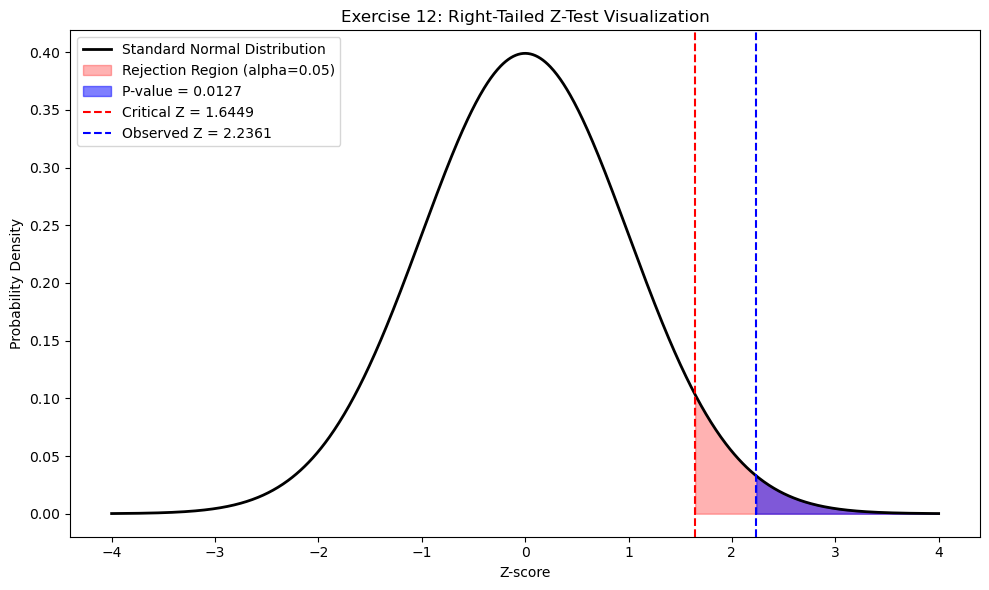

In [17]:
# Part 2: Visualization

x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, 0, 1)

plt.figure(figsize=(10, 6))
plt.plot(x, y, 'k-', lw=2, label='Standard Normal Distribution')

# Shade rejection region (right tail)
x_reject = np.linspace(z_critical, 4, 200)
y_reject = stats.norm.pdf(x_reject, 0, 1)
plt.fill_between(x_reject, y_reject, color='red', alpha=0.3,
                 label=f'Rejection Region (alpha={alpha})')

# Shade p-value area
x_pval = np.linspace(z_stat, 4, 200)
y_pval = stats.norm.pdf(x_pval, 0, 1)
plt.fill_between(x_pval, y_pval, color='blue', alpha=0.5,
                 label=f'P-value = {p_value:.4f}')

# Mark critical value and observed Z
plt.axvline(z_critical, color='red', linestyle='--', lw=1.5,
            label=f'Critical Z = {z_critical:.4f}')
plt.axvline(z_stat, color='blue', linestyle='--', lw=1.5,
            label=f'Observed Z = {z_stat:.4f}')

plt.title('Exercise 12: Right-Tailed Z-Test Visualization')
plt.xlabel('Z-score')
plt.ylabel('Probability Density')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

---

## Data Science Connection

Every exercise above maps directly to real-world data science workflows:

| Exercise Context | Data Science Application |
|------------------|--------------------------|
| Customer support resolution time | Monitoring SLA metrics after deploying ML-based routing |
| QA tablet dosage | Automated anomaly detection in manufacturing IoT data |
| E-commerce order value | Evaluating the impact of a website/UX change on revenue KPIs |
| A/B email campaign | Experiment design and analysis in marketing analytics |
| Minimum sample size | Power analysis before launching an A/B test |
| Loan processing time | Operational analytics and process improvement |

In `scikit-learn` and production ML pipelines, you rarely call `ztest()` directly — but the **reasoning** (Is this difference real or noise?) underpins every model evaluation, feature selection, and deployment decision you will make.